# One dose-response curve

How does an outcome change as a continuous dose changes? This notebook simulates data with a known curve
(an inverted U, peaking mid-range), fits `drcurves` with its defaults, and reads the results.

In your own data, swap the simulation for your covariates `X`, dose `A` and outcome `Y`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from drcurves import fit_dose_response
from drcurves.simulate import sim_nonlinear

X, A, Y, truth = sim_nonlinear(n=3000, curve="inverted_u_centred", seed=1)
X.shape, A[:5].round(2)

((3000, 5), array([-0.22, -0.56,  0.32,  0.61,  1.36]))

## Fit

`fit_dose_response` cross-fits an outcome model and a model for the dose, builds doubly robust
pseudo-outcomes, and smooths them into a curve. Both models default to a stack of a spline regression
and gradient boosting.

In [2]:
model = fit_dose_response(X, A, Y)

## Check before you trust it

`diagnostics()` reports how extreme the weights are (`ess_share` is the weights' effective sample size as a
share of n; low means a few units dominate), the dose range the curve was fitted on, and the smoothing chosen.

In [3]:
d = model.diagnostics()
d["weights"], d["dose_range_fitted"]

({'median': 0.6523259508486157,
  'p99': 5.258929189747564,
  'max_raw': 1744203.8346124256,
  'cap': 5.258929189747564,
  'share_capped': 0.01,
  'ess_share': 0.5380785556580889},
 (-2.5305502187644318, 2.728701640063752))

## The curve

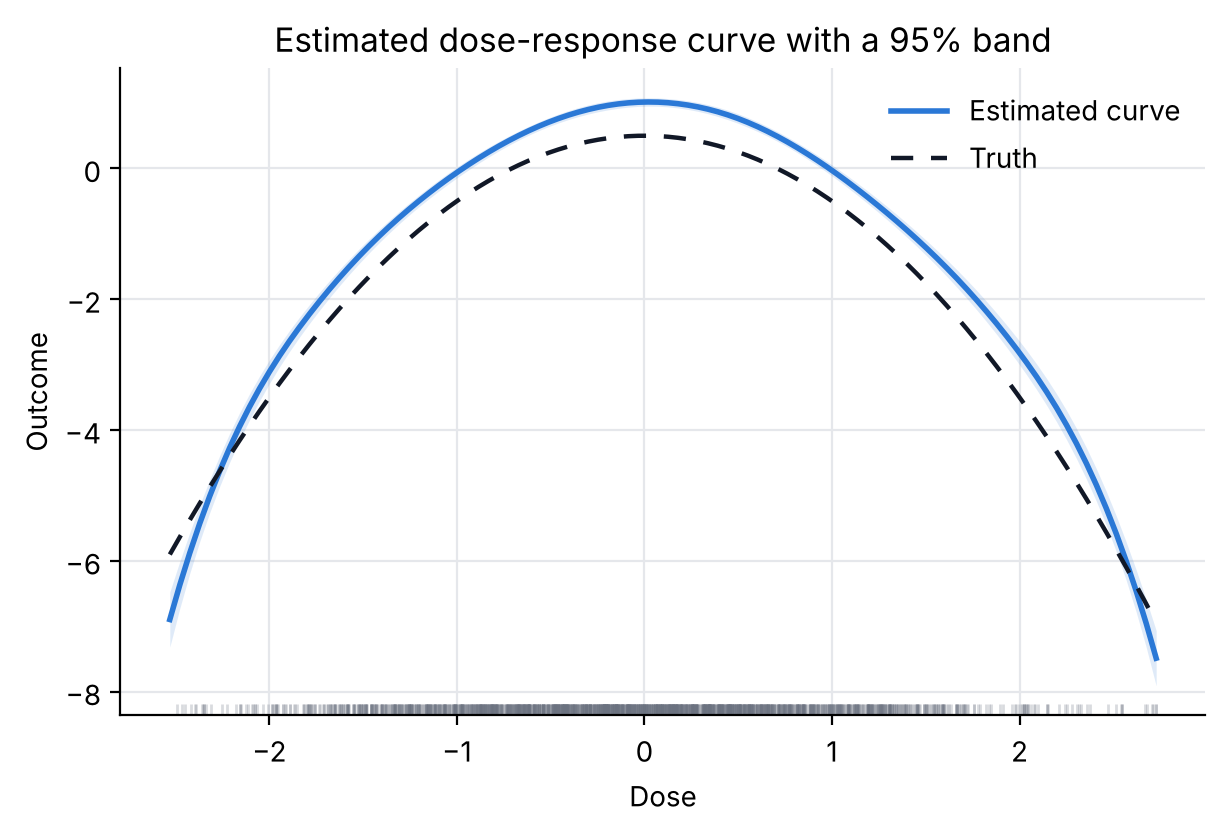

In [4]:
ax = model.plot(truth=truth)
ax.set_title("Estimated dose-response curve with a 95% band");

## Answers to decision questions

- **Contrast:** what happens if we move the dose from one value to another?
- **Optimal dose:** where does the curve peak, and how sure are we? `at_edge` is the share of simulated curves
  whose peak sits at the end of the grid; if large, the optimum may lie outside the data.

In [5]:
lift, se = model.contrast(-1.0, 0.0)
print(f"Moving the dose from -1 to 0 changes the outcome by {lift:.2f} (s.e. {se:.2f})")

grid = np.linspace(*np.quantile(A, [0.05, 0.95]), 61)
best = model.optimal_dose(grid)
print(f"Best dose {best['dose']:.2f}, 95% interval {best['lo']:.2f} to {best['hi']:.2f}, at edge {best['at_edge']:.0%}")

Moving the dose from -1 to 0 changes the outcome by 1.08 (s.e. 0.05)
Best dose 0.04, 95% interval -0.06 to 0.09, at edge 0%


## When a stable trait you can't measure drives the dose

If you have the outcome from before the dose, difference-in-differences removes stable unobserved traits.
Here a hidden trait raises both the dose and the outcome. Adjusting for X alone is biased; fitting on the
change (`y_pre=`) recovers the curve. A placebo on two pre-periods should be flat.

Placebo: largest deviation is 2.6% of the real curve's range


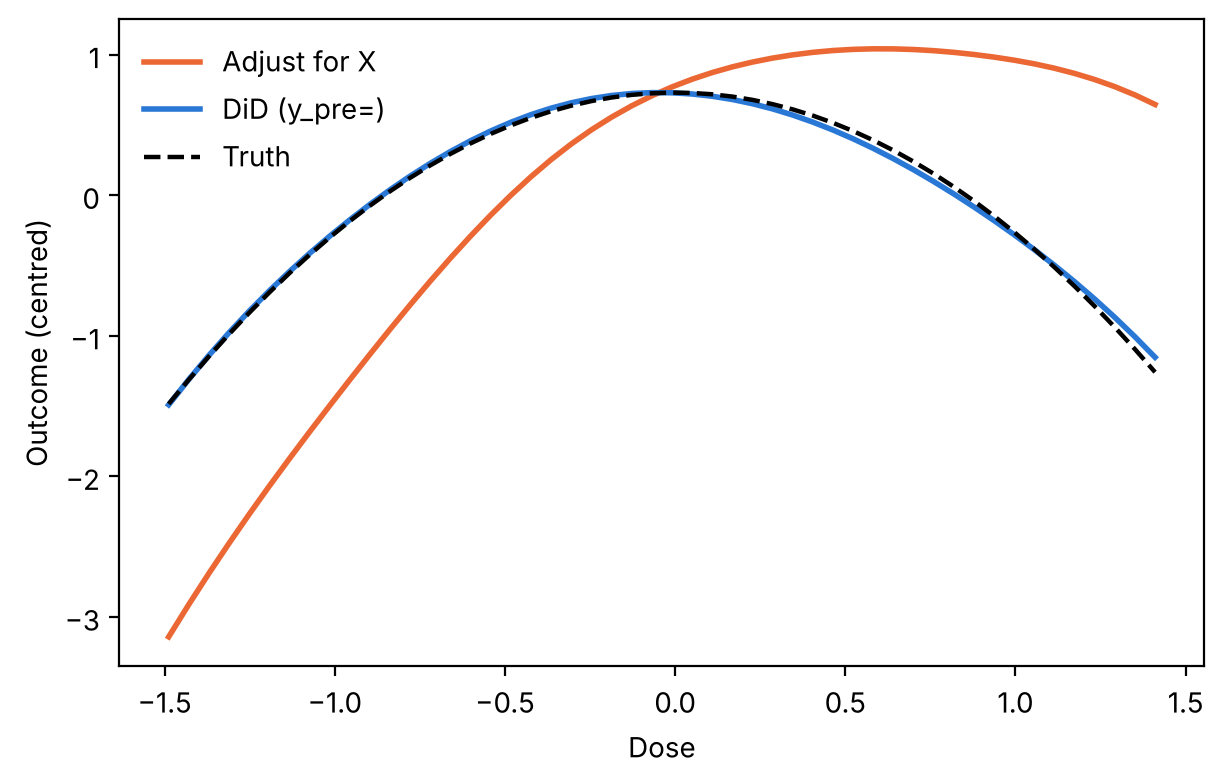

In [6]:
from drcurves import placebo_check
from drcurves.simulate import sim_did

Xd, Ad, Yd, f = sim_did(n=3000, seed=0)
levels = fit_dose_response(Xd, Ad, Yd[1])
did = fit_dose_response(Xd, Ad, Yd[1], y_pre=Yd[0])

g = np.linspace(*np.quantile(Ad, [0.05, 0.95]), 50)
fig, ax = plt.subplots(figsize=(7, 4.2))
for m, lab, col in [(levels, "Adjust for X", "#eb6834"), (did, "DiD (y_pre=)", "#2a78d6")]:
    ax.plot(g, m.curve(g, centre=True)[0], color=col, lw=2, label=lab)
t = f(g); ax.plot(g, t - t.mean(), "k--", lw=1.6, label="Truth")
ax.legend(frameon=False); ax.set_xlabel("Dose"); ax.set_ylabel("Outcome (centred)")

pc = placebo_check(Xd, Ad, Yd[0], Yd[-1], main=did)
print(f"Placebo: largest deviation is {pc['relative']:.1%} of the real curve's range")